# MLP_JK_Best_PLS — the second reference model

**What this model is.** The same model as MLP_JK_Best (setup **E**: the spot's own embedding plus the average embedding of its 5×5 neighborhood; the **V_clean** genes; raw log1p target; the same MLP head and training). The only change is the step that shrinks each 4,608-number embedding before the MLP: **kernel PLS with 32 components per block** instead of PCA with 256. This is the "PLS, k=32" setting from MLP_JK_11.

**Why we keep two references.**
- On validation patients (what we choose by), PLS 32 and PCA 256 tie: validation PCC 0.2385 vs. 0.2376. Neither clearly beats the other.
- On the test patients, PLS 32 has a higher pooled PCC (0.253 vs. 0.205). Most of that gain comes from getting each patient's overall level right (patient-level accuracy). Inside each patient, the spot-to-spot patterns are predicted about equally well (within-patient PCC 0.176 vs. 0.173).
- PLS 32 gives the head 64 numbers per spot; PCA 256 gives it 512. The head is about 5 times smaller.
- PCA never looks at the genes and is faster to fit. PLS uses the genes, so it must be refit for every set of training patients, and it can only be used where the genes are known.

So from now on, every experiment is compared against both. The two references and the bar to beat are written once in `results/best_references.json`.

**Leakage rule.** PLS uses the genes, so it never sees the patients it is scored on. For validation, PLS is fit on each inner group's fit patients only. For test, it is refit on all of the fold's training patients.

**Check.** This notebook must reproduce MLP_JK_11's "PLS k=32" row, or it stops.

**Reads** `~/JHU/BDD/datasets/BDD_HEST` (read only), `results/standard_gene_rule.json`, `results/gene_symbols.csv`, `results/MLP_JK_Best/` and `results/MLP_JK_11/`.
**Saves** to `results/MLP_JK_Best_PLS/`, adds one row to `results/all_results.csv`, and writes `results/best_references.json`. MLP_JK_Best and MLP_JK_11 are not changed.

In [1]:
import os
import copy
import json
import time
import datetime
import numpy as np
import pandas as pd
import scipy.sparse
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from sklearn.model_selection import GroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors

## Settings

**Paths:** `BEST_DIR` (MLP_JK_Best's results, for the gene check and the comparison), `REFERENCE_DIR` (MLP_JK_11's results, for the reproduction check), `REFERENCES_FILE` (the two-reference file this notebook writes).

**The projection:** `N_COMPONENTS = 32` kernel PLS components per block (center, 5×5 average), so the head gets 64 inputs.

**Everything else** is the same as MLP_JK_Best and MLP_JK_11.

**Check tolerances:** the same as before (test MSE and NRMSE 0.005, PCC 0.01, validation PCC 0.005).

In [2]:
DATA_DIR = os.path.expanduser("~/JHU/BDD/datasets/BDD_HEST")
MLP_DIR = os.path.expanduser("~/JHU/BDD/MLP_JK")
RESULTS_DIR = os.path.join(MLP_DIR, "results")
RULE_FILE = os.path.join(RESULTS_DIR, "standard_gene_rule.json")
SYMBOLS_FILE = os.path.join(RESULTS_DIR, "gene_symbols.csv")
BEST_DIR = os.path.join(RESULTS_DIR, "MLP_JK_Best")
REFERENCE_DIR = os.path.join(RESULTS_DIR, "MLP_JK_11")
REFERENCES_FILE = os.path.join(RESULTS_DIR, "best_references.json")
RESULTS_LOG = os.path.join(RESULTS_DIR, "all_results.csv")
NOTEBOOK_NAME = "MLP_JK_Best_PLS"
MODEL_NAME = "E 5x5 average, PLS k=32"
PCA_MODEL_NAME = "E 5x5 average"
LOG_RESULTS = True
OUT_DIR = os.path.join(RESULTS_DIR, NOTEBOOK_NAME)

N_COMPONENTS = 32

N_FOLDS = 4
MIN_TEST_SD = 0.05
SEED = 0

NEIGHBOR_DISTANCE = {"5x5": 3.0}

HIDDEN_SIZE = 128
DROPOUT = 0.3
WEIGHT_DECAY = 1e-3
LEARNING_RATE = 3e-4
BATCH_SIZE = 256
MAX_EPOCHS = 100
PATIENCE = 10
SHRINK_FACTORS = [0.2, 0.4, 0.6, 0.8, 1.0]
N_VAL_GROUPS = 4
N_FINAL_SEEDS = 3

CHECK_MSE_TOLERANCE = 0.005
CHECK_PCC_TOLERANCE = 0.01
CHECK_VAL_PCC_TOLERANCE = 0.005

The gene rule, the device (Apple GPU `mps` if available, otherwise CPU) and fixed seeds. The Apple GPU isn't perfectly deterministic, so a rerun can differ in the third decimal.

In [3]:
with open(RULE_FILE) as f:
    gene_rule = json.load(f)
EXCLUDE_PREFIX = gene_rule["exclude_prefix"]
MIN_DETECTION = gene_rule["min_detection"]
N_GENES = gene_rule["n_genes"]
GENE_LIST = gene_rule["name"]
print(f"Gene list {GENE_LIST}: exclude '{EXCLUDE_PREFIX}...', detection >= {MIN_DETECTION}, top {N_GENES} by variance")

if torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")
print("Device:", device)

np.random.seed(SEED)
torch.manual_seed(SEED)

EXPRESSION_DIR = os.path.join(DATA_DIR, "expression")
EMBEDDING_DIR = os.path.join(DATA_DIR, "embeddings")
os.makedirs(OUT_DIR, exist_ok=True)


def save_figure(name):
    plt.savefig(os.path.join(OUT_DIR, name), dpi=150, bbox_inches="tight")

Gene list V_clean: exclude '__...', detection >= 0.1, top 50 by variance
Device: mps


## Step 1. Load embeddings and expression (copied from Notebook 5)

Each section's embedding file must list the same barcodes, in the same order, as the spot table, and each expression matrix must have one row per spot and one column per gene. The `assert` lines stop the notebook if not.

In [4]:
spot_table = pd.read_csv(os.path.join(DATA_DIR, "spot_table.csv"))
with open(os.path.join(DATA_DIR, "genes.txt")) as f:
    all_genes = np.array(f.read().split())

X_parts = []
Y_parts = []
spot_parts = []

for sample_id in spot_table["sample_id"].unique():
    section_spots = spot_table[spot_table["sample_id"] == sample_id].sort_values("row_in_sample")

    saved = np.load(os.path.join(EMBEDDING_DIR, f"{sample_id}.npz"), allow_pickle=True)
    assert np.array_equal(saved["barcode"], section_spots["barcode"].to_numpy()), \
        f"{sample_id}: embedding rows don't match the spot table"

    expression = scipy.sparse.load_npz(os.path.join(EXPRESSION_DIR, f"{sample_id}.npz"))
    assert expression.shape == (len(section_spots), len(all_genes)), \
        f"{sample_id}: expression shape doesn't match the spot table and genes.txt"

    X_parts.append(saved["embeddings"].astype(np.float32))
    Y_parts.append(expression)
    spot_parts.append(section_spots)

X_raw = np.concatenate(X_parts, axis=0)
Y = scipy.sparse.vstack(Y_parts).tocsc()
spots = pd.concat(spot_parts, ignore_index=True)
del X_parts, Y_parts
patient_array = spots["patient"].to_numpy()
section_array = spots["sample_id"].to_numpy()

print("X (embeddings):", X_raw.shape)
print("Y (log1p expression):", Y.shape)
print("Sections:", spots["sample_id"].nunique(), " Patients:", spots["patient"].nunique())

section_ids = np.unique(section_array)
section_number = np.searchsorted(section_ids, section_array)

X (embeddings): (30600, 4608)
Y (log1p expression): (30600, 11787)
Sections: 68  Patients: 23


## Step 2. Neighborhoods and patient folds (copied from MLP_JK_03)

The 5×5 neighborhood: every spot on the same section within 3.0 spot spacings, including the spot itself. Folds: `GroupKFold` by patient, the same 4 folds as always.

In [5]:
def find_neighborhoods(max_distance):
    neighborhoods = [None] * len(spots)
    for sample_id in np.unique(section_array):
        rows = np.where(section_array == sample_id)[0]
        xy = spots.loc[rows, ["x", "y"]].to_numpy().astype(np.float64)
        finder = NearestNeighbors().fit(xy)
        distances, _ = finder.kneighbors(xy, n_neighbors=2)
        spacing = np.median(distances[:, 1])
        nearby_lists = finder.radius_neighbors(xy, radius=max_distance * spacing, return_distance=False)
        for i, nearby in enumerate(nearby_lists):
            neighborhoods[rows[i]] = rows[nearby]
    return neighborhoods


def neighbor_mean(X, neighborhoods):
    X_smoothed = np.zeros_like(X)
    for i, nearby in enumerate(neighborhoods):
        X_smoothed[i] = X[nearby].mean(axis=0)
    return X_smoothed


neighborhoods = {}
for name, distance in NEIGHBOR_DISTANCE.items():
    neighborhoods[name] = find_neighborhoods(distance)
    sizes = np.array([len(n) for n in neighborhoods[name]])
    full = 9 if name == "3x3" else 25
    print(f"{name}: spots per neighborhood (incl. itself) mean {sizes.mean():.2f}, "
          f"min {sizes.min()}, max {sizes.max()} | full ({full}): {np.mean(sizes == full):.1%}")

5x5: spots per neighborhood (incl. itself) mean 21.25, min 2, max 27 | full (25): 18.2%


In [6]:
fold_of_spot = np.zeros(len(spots), dtype=int)
splitter = GroupKFold(n_splits=N_FOLDS)
for fold, (train_index, test_index) in enumerate(splitter.split(X_raw, groups=patient_array)):
    fold_of_spot[test_index] = fold

for fold in range(N_FOLDS):
    print(f"fold {fold}: {np.sum(fold_of_spot == fold)} test spots | {sorted(np.unique(patient_array[fold_of_spot == fold]))}")

fold_train_index = [np.where(fold_of_spot != fold)[0] for fold in range(N_FOLDS)]
fold_test_index = [np.where(fold_of_spot == fold)[0] for fold in range(N_FOLDS)]

fold 0: 7625 test spots | ['BC23209', 'BC23803', 'BC23810', 'BC23895', 'BC23901', 'BC23903']
fold 1: 7950 test spots | ['BC23268', 'BC23287', 'BC23377', 'BC23450', 'BC23506', 'BC24220']
fold 2: 7876 test spots | ['BC23269', 'BC23270', 'BC23277', 'BC23508', 'BC23567', 'BC24105']
fold 3: 7149 test spots | ['BC23272', 'BC23288', 'BC23944', 'BC24044', 'BC24223']


## Step 3. The gene list, V_clean, from the rule file

The same as MLP_JK_Best: per fold, on training spots only, drop the excluded bins, keep genes with count > 0 in at least 10% of the spots, take the top 50 by variance. The lists must equal MLP_JK_Best's genes in every fold.

In [7]:
symbols = pd.read_csv(SYMBOLS_FILE)
symbol_of = dict(zip(symbols["ensembl_id"], symbols["symbol"]))
is_excluded = np.char.startswith(all_genes.astype(str), EXCLUDE_PREFIX)


def standard_genes(train_index):
    Y_train = Y[train_index]
    detection = np.asarray((Y_train > 0).mean(axis=0)).ravel()
    mean = np.asarray(Y_train.mean(axis=0)).ravel()
    variance = np.asarray(Y_train.multiply(Y_train).mean(axis=0)).ravel() - mean ** 2
    candidates = np.where(~is_excluded & (detection >= MIN_DETECTION))[0]
    return candidates[np.argsort(variance[candidates])[::-1][:N_GENES]]


fold_genes = [standard_genes(fold_train_index[fold]) for fold in range(N_FOLDS)]

reference_genes = pd.read_csv(os.path.join(BEST_DIR, "genes.csv"))
for fold in range(N_FOLDS):
    saved = reference_genes[reference_genes["fold"] == fold].sort_values("rank")["ensembl_id"].tolist()
    assert saved == list(all_genes[fold_genes[fold]]), f"fold {fold}: genes differ from MLP_JK_Best"
print("V_clean equals MLP_JK_Best's genes in every fold.")
for fold in range(N_FOLDS):
    print(f"fold {fold}: " + ", ".join(symbol_of[g] for g in all_genes[fold_genes[fold]][:10]) + ", ...")

V_clean equals MLP_JK_Best's genes in every fold.
fold 0: IGLL5, TFF3, MUC1, RPS3, S100A9, H2AJ, MGP, ERBB2, KRT19, NHERF1, ...
fold 1: TFF3, IGLL5, S100A9, ERBB2, NHERF1, MUC1, COX6C, MGP, KRT19, B2M, ...
fold 2: TFF3, IGLL5, RPS3, ERBB2, KRT19, MUC1, MGP, NHERF1, H2AJ, AZGP1, ...
fold 3: TFF3, IGLL5, RPS3, ERBB2, H2AJ, MUC1, MGP, KRT19, NHERF1, S100A9, ...


## Step 4. Scoring and the error split

**`score_model`** (copied from Notebook 5): per gene, pooled PCC and NRMSE (genes with test SD < 0.05 get no NRMSE), and the same within each test patient.

**`error_parts`** (from MLP_JK_06): a fold's MSE split into **level error** (each test slide's predicted mean vs. its true mean) and **pattern error** (what's left inside each slide). It checks that the two add up to the MSE.

**`score_results`**: the per-fold and overall scores, as in MLP_JK_11.

In [8]:
def pcc(a, b):
    if np.std(a) < 1e-6 or np.std(b) < 1e-6:
        return np.nan
    return np.corrcoef(a, b)[0, 1]


def score_model(model_name, fold_results, prediction_key):
    pooled_rows = []
    within_rows = []
    for r in fold_results:
        y_true = r["y_test"]
        y_pred = r[prediction_key]
        test_patients = patient_array[r["test_index"]]

        for g, gene in enumerate(r["genes"]):
            sd = np.std(y_true[:, g])
            rmse = np.sqrt(np.mean((y_true[:, g] - y_pred[:, g]) ** 2))
            pooled_rows.append({
                "model": model_name, "fold": r["fold"], "gene": gene,
                "PCC": pcc(y_true[:, g], y_pred[:, g]),
                "NRMSE": rmse / sd if sd >= MIN_TEST_SD else np.nan,
                "alpha": r["alpha"][g] if prediction_key == "y_pred" else np.nan,
            })

        for patient in np.unique(test_patients):
            rows = test_patients == patient
            for g, gene in enumerate(r["genes"]):
                t = y_true[rows, g]
                p = y_pred[rows, g]
                sd = np.std(t)
                if sd < MIN_TEST_SD:
                    continue
                centered_mse = np.mean(((t - t.mean()) - (p - p.mean())) ** 2)
                within_rows.append({
                    "model": model_name, "fold": r["fold"], "patient": patient, "gene": gene,
                    "PCC_within": pcc(t, p),
                    "NRMSE_within": np.sqrt(np.mean((t - p) ** 2)) / sd,
                    "NRMSE_centered": np.sqrt(centered_mse) / sd,
                })
    return pd.DataFrame(pooled_rows), pd.DataFrame(within_rows)


def split_error(y_true, y_pred, rows):
    sections = section_number[rows]
    level_error = np.zeros(y_true.shape[1])
    pattern_error = np.zeros(y_true.shape[1])
    for s in np.unique(sections):
        in_section = sections == s
        error = y_true[in_section] - y_pred[in_section]
        share = in_section.mean()
        level_error += share * error.mean(axis=0) ** 2
        pattern_error += share * error.var(axis=0)
    return level_error.mean(), pattern_error.mean()


def error_parts(result):
    scored = result["y_test"].std(axis=0) >= MIN_TEST_SD
    y_true = result["y_test"][:, scored]
    y_pred = result["y_pred"][:, scored]
    mse = np.mean((y_true - y_pred) ** 2)
    level_error, pattern_error = split_error(y_true, y_pred, result["test_index"])
    assert abs(level_error + pattern_error - mse) < 1e-6, "level + pattern doesn't add up to the MSE"
    return mse, level_error, pattern_error, scored.sum()


def score_results(fold_results, model_name):
    pooled, within = score_model(model_name, fold_results, "y_pred")
    rows = []
    for r in fold_results:
        mse, level_error, pattern_error, n_scored = error_parts(r)
        fold = r["fold"]
        rows.append({
            "model": model_name, "fold": fold, "MSE": mse, "level_error": level_error,
            "pattern_error": pattern_error, "genes_scored": n_scored,
            "PCC": pooled.loc[pooled["fold"] == fold, "PCC"].mean(),
            "NRMSE": pooled.loc[pooled["fold"] == fold, "NRMSE"].mean(),
            "PCC_within": within.loc[within["fold"] == fold, "PCC_within"].mean(),
        })
    folds = pd.DataFrame(rows)
    folds["level_share"] = folds["level_error"] / folds["MSE"]
    n = folds["genes_scored"]
    overall = {
        "test_MSE": np.sum(folds["MSE"] * n) / n.sum(),
        "pooled_PCC": pooled["PCC"].mean(),
        "within_PCC": within["PCC_within"].mean(),
        "NRMSE": pooled["NRMSE"].mean(),
        "level_error": np.sum(folds["level_error"] * n) / n.sum(),
        "pattern_error": np.sum(folds["pattern_error"] * n) / n.sum(),
    }
    overall["level_share"] = overall["level_error"] / overall["test_MSE"]
    return folds, overall, pooled, within

## Step 5. The MLP head and training (the same as MLP_JK_Best)

**The head:** Linear(64, 128) → ReLU → Dropout 0.3 → Linear(128, 50). Adam lr 3e-4, weight decay 1e-3, MSE loss on standardized genes, batches of 256, early stopping with patience 10 on validation patients. `shrink` = `train_mean + s × (prediction − train_mean)`.

In [9]:
class MLP(nn.Module):
    def __init__(self, n_inputs, n_hidden, n_outputs, dropout):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(n_inputs, n_hidden),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(n_hidden, n_outputs),
        )

    def forward(self, x):
        return self.layers(x)


def to_device(array):
    return torch.tensor(np.asarray(array), dtype=torch.float32, device=device)


def predict(trained, P_device, rows):
    model = trained["model"]
    model.eval()
    outputs = []
    with torch.no_grad():
        for start in range(0, len(rows), 4096):
            batch_rows = torch.tensor(rows[start:start + 4096], device=device)
            outputs.append(model(P_device[batch_rows]).cpu().numpy())
    y_scaled = np.concatenate(outputs, axis=0)
    return y_scaled * trained["gene_sd"] + trained["gene_mean"]


def shrink(y_pred, train_mean, k):
    return train_mean + k * (y_pred - train_mean)


def train_mlp(P_device, y_fold, train_rows, val_rows, n_epochs, seed):
    torch.manual_seed(seed)
    rng = np.random.default_rng(seed)

    gene_mean = y_fold[train_rows].mean(axis=0)
    gene_sd = y_fold[train_rows].std(axis=0)
    y_scaled = to_device((y_fold - gene_mean) / gene_sd)

    model = MLP(P_device.shape[1], HIDDEN_SIZE, N_GENES, DROPOUT).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    loss_function = nn.MSELoss()

    trained = {
        "model": model,
        "gene_mean": gene_mean,
        "gene_sd": gene_sd,
        "history": [],
        "best_epoch": n_epochs,
    }

    best_val_loss = np.inf
    best_weights = None
    for epoch in range(1, n_epochs + 1):
        model.train()
        shuffled = rng.permutation(train_rows)
        batch_losses = []
        for start in range(0, len(shuffled), BATCH_SIZE):
            batch_rows = torch.tensor(shuffled[start:start + BATCH_SIZE], device=device)
            loss = loss_function(model(P_device[batch_rows]), y_scaled[batch_rows])
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            batch_losses.append(loss.item())
        train_loss = np.mean(batch_losses)

        if val_rows is None:
            trained["history"].append({"epoch": epoch, "train_loss": train_loss, "val_loss": np.nan})
            continue

        val_pred = predict(trained, P_device, val_rows)
        val_loss = np.mean(((val_pred - y_fold[val_rows]) / gene_sd) ** 2)
        trained["history"].append({"epoch": epoch, "train_loss": train_loss, "val_loss": val_loss})

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            trained["best_epoch"] = epoch
            best_weights = copy.deepcopy(model.state_dict())
        elif epoch - trained["best_epoch"] >= PATIENCE:
            break

    if best_weights is not None:
        model.load_state_dict(best_weights)
    return trained


def count_weights(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

## Step 6. Kernel PLS (the same function as MLP_JK_11)

**Standardized embeddings.** For each fold, one StandardScaler per block (center, 5×5 average), fit on the fold's training spots, as in MLP_JK_Best.

**Kernel PLS** (Dayal & MacGregor 1997): finds the directions in the embedding that best predict the 50 genes. It gives the same components as sklearn's `PLSRegression` (scaled, NIPALS) but runs much faster because it works from XᵀX and XᵀY. In MLP_JK_11 it matched fully converged sklearn PLS to correlation > 0.99999 on every component.

**PLS outputs go to the head unscaled**, just as the PCA outputs do in MLP_JK_Best.

**`prepare_fold`** fits PLS 5 times per block: once on each of the 4 inner groups' fit patients (for validation) and once on all of the fold's training patients (`"final"`, for test). Y is the fold's 50 V_clean genes.

In [10]:
X_mean_5x5 = neighbor_mean(X_raw, neighborhoods["5x5"])


def standardize(fold):
    train_index = fold_train_index[fold]
    blocks = {}
    for block, X in [("center", X_raw), ("mean_5x5", X_mean_5x5)]:
        scaler = StandardScaler()
        scaler.fit(X[train_index])
        blocks[block] = scaler.transform(X).astype(np.float32)
    return blocks

def kernel_pls_fit(X, Y, n_components):
    start = time.perf_counter()
    x_mean = X.mean(axis=0)
    x_sd = X.std(axis=0, ddof=1)
    x_sd[x_sd == 0] = 1.0
    Xs = ((X - x_mean) / x_sd).astype(np.float64)
    y_sd = Y.std(axis=0, ddof=1)
    y_sd[y_sd == 0] = 1.0
    Ys = (Y - Y.mean(axis=0)) / y_sd
    XtX = Xs.T @ Xs
    XtY = Xs.T @ Ys
    del Xs
    setup_seconds = time.perf_counter() - start

    n_features = X.shape[1]
    weights = np.zeros((n_features, n_components))
    rotations = np.zeros((n_features, n_components))
    loadings = np.zeros((n_features, n_components))
    seconds_after = np.zeros(n_components)
    for a in range(n_components):
        eigenvalues, eigenvectors = np.linalg.eigh(XtY.T @ XtY)
        w = XtY @ eigenvectors[:, -1]
        w /= np.linalg.norm(w)
        w *= np.sign(w[np.argmax(np.abs(w))])
        r = w - rotations[:, :a] @ (loadings[:, :a].T @ w)
        XtX_r = XtX @ r
        tt = r @ XtX_r
        p = XtX_r / tt
        q = XtY.T @ r / tt
        XtY -= tt * np.outer(p, q)
        weights[:, a] = w
        rotations[:, a] = r
        loadings[:, a] = p
        seconds_after[a] = time.perf_counter() - start
    return {"mean": x_mean, "sd": x_sd, "weights": weights, "rotations": rotations,
            "setup_seconds": setup_seconds, "seconds_after": seconds_after}


def kernel_pls_transform(fit, Z, k):
    return (((Z - fit["mean"]) / fit["sd"]) @ fit["rotations"][:, :k]).astype(np.float32)



def validation_groups(train_index):
    groups = patient_array[train_index]
    splits = []
    for inner_fit, inner_val in GroupKFold(n_splits=N_VAL_GROUPS).split(train_index, groups=groups):
        splits.append((train_index[inner_fit], train_index[inner_val]))
    return splits


def prepare_fold(fold):
    train_index = fold_train_index[fold]
    Z = standardize(fold)
    y_genes = Y[:, fold_genes[fold]].toarray()
    row_sets = {group: fit_rows for group, (fit_rows, _) in enumerate(validation_groups(train_index))}
    row_sets["final"] = train_index
    features = {}
    for name, rows in row_sets.items():
        fits = [kernel_pls_fit(Z[block][rows], y_genes[rows], N_COMPONENTS) for block in ["center", "mean_5x5"]]
        features[name] = np.concatenate([kernel_pls_transform(fit, Z[block], N_COMPONENTS)
                                         for fit, block in zip(fits, ["center", "mean_5x5"])], axis=1)
    return features

## Step 7. One fold, start to finish

| Step | Uses |
|---|---|
| V_clean, gene means and SDs | training patients |
| For each of the 4 validation groups | PLS fit on the group's fit patients; the MLP trained on them, early stopping on the validation patients |
| `s` | lowest validation NRMSE averaged over the 4 groups |
| Epochs | median best epoch over the 4 groups |
| Final model | PLS refit on **all** training patients; the MLP trained on them with 3 seeds, averaged |
| Test patients | used once, for scoring |

The test spots' expression is `NaN` in every array the training reads.

In [11]:
def run_fold(fold, features):
    if device.type == "mps":
        torch.mps.empty_cache()
    gene_index = fold_genes[fold]
    genes = all_genes[gene_index]
    train_index = fold_train_index[fold]
    test_index = fold_test_index[fold]
    no_alpha = np.full(N_GENES, np.nan)

    y_fold = Y[:, gene_index].toarray()
    y_fold[test_index] = np.nan
    y_test = Y[test_index][:, gene_index].toarray()
    train_mean = y_fold[train_index].mean(axis=0)

    val_rows = []
    for group, (fit_rows, val_index) in enumerate(validation_groups(train_index)):
        P_device = to_device(features[group])
        fit_mean = y_fold[fit_rows].mean(axis=0)
        val_result = {"fold": fold, "test_index": val_index, "genes": genes, "y_test": y_fold[val_index],
                      "y_mean": np.tile(fit_mean, (len(val_index), 1)), "alpha": no_alpha}
        mean_scores, _ = score_model("mean predictor", [val_result], "y_mean")

        trained = train_mlp(P_device, y_fold, fit_rows, val_index, MAX_EPOCHS, SEED)
        val_pred = predict(trained, P_device, val_index)
        for s in SHRINK_FACTORS:
            val_result["y_pred"] = shrink(val_pred, fit_mean, s)
            scores, _ = score_model("MLP", [val_result], "y_pred")
            val_rows.append({"model": MODEL_NAME, "fold": fold, "val_group": group, "s": s,
                             "val_PCC": scores["PCC"].mean(), "val_NRMSE": scores["NRMSE"].mean(),
                             "val_mean_predictor_NRMSE": mean_scores["NRMSE"].mean(),
                             "best_epoch": trained["best_epoch"]})

    val_table = pd.DataFrame(val_rows)
    by_s = val_table.groupby("s").agg(val_PCC=("val_PCC", "mean"), val_NRMSE=("val_NRMSE", "mean"),
                                      val_mean_predictor_NRMSE=("val_mean_predictor_NRMSE", "mean"),
                                      epochs=("best_epoch", "median")).reset_index()
    chosen = by_s.loc[by_s["val_NRMSE"].idxmin()].to_dict()
    chosen["final_epochs"] = max(1, int(round(chosen["epochs"])))
    chosen["passes"] = chosen["val_NRMSE"] <= chosen["val_mean_predictor_NRMSE"]
    chosen["val_best_epochs"] = "/".join(str(e) for e in val_table.drop_duplicates("val_group")["best_epoch"])
    chosen["fold"] = fold

    P_device = to_device(features["final"])
    seed_predictions = []
    for seed_number in range(N_FINAL_SEEDS):
        final = train_mlp(P_device, y_fold, train_index, None, chosen["final_epochs"], SEED + seed_number)
        seed_predictions.append(predict(final, P_device, test_index))
    chosen["head_weights"] = count_weights(final["model"])
    del P_device, final

    test_result = {"fold": fold, "test_index": test_index, "genes": genes, "y_test": y_test,
                   "y_pred": shrink(np.mean(seed_predictions, axis=0), train_mean, chosen["s"]), "alpha": no_alpha}
    seed_results = [dict(test_result, y_pred=shrink(p, train_mean, chosen["s"])) for p in seed_predictions]
    mean_result = dict(test_result, y_pred=np.tile(train_mean, (len(test_index), 1)))
    return test_result, seed_results, mean_result, val_table, chosen

## Step 8. Run every fold

For each fold: the PLS features (10 kernel PLS fits: 2 blocks × 5 sets of patients), then the MLP.

In [12]:
results = []
seed_results = [[] for _ in range(N_FINAL_SEEDS)]
mean_results = []
val_tables = []
chosen_rows = []

start_time = time.time()
for fold in range(N_FOLDS):
    features = prepare_fold(fold)
    print(f"fold {fold}: PLS features ready ({(time.time() - start_time) / 60:.1f} min)", flush=True)
    test_result, seeds, mean_result, val_table, chosen = run_fold(fold, features)
    results.append(test_result)
    for seed_number, seed_result in enumerate(seeds):
        seed_results[seed_number].append(seed_result)
    mean_results.append(mean_result)
    val_tables.append(val_table)
    chosen_rows.append(chosen)
    print(f"fold {fold}: done, s = {chosen['s']}, {chosen['final_epochs']} epochs "
          f"({(time.time() - start_time) / 60:.1f} min)", flush=True)
    del features

val_scores = pd.concat(val_tables, ignore_index=True)
chosen_settings = pd.DataFrame(chosen_rows)[["fold", "s", "val_PCC", "val_NRMSE", "val_mean_predictor_NRMSE",
                                              "passes", "epochs", "final_epochs", "val_best_epochs", "head_weights"]]
print(chosen_settings.round(4).to_string(index=False))

fold 0: PLS features ready (0.5 min)


fold 0: done, s = 0.6, 34 epochs (0.9 min)


fold 1: PLS features ready (1.4 min)


fold 1: done, s = 0.4, 28 epochs (1.6 min)


fold 2: PLS features ready (2.2 min)


fold 2: done, s = 0.6, 25 epochs (2.4 min)


fold 3: PLS features ready (3.0 min)


fold 3: done, s = 0.4, 26 epochs (3.2 min)


 fold   s  val_PCC  val_NRMSE  val_mean_predictor_NRMSE  passes  epochs  final_epochs val_best_epochs  head_weights
    0 0.6   0.3034     1.0981                    1.1441    True    33.5            34     20/36/34/33         14770
    1 0.4   0.1984     1.0969                    1.1268    True    28.5            28     39/38/11/19         14770
    2 0.6   0.2137     1.0535                    1.0978    True    25.0            25     31/25/13/25         14770
    3 0.4   0.2386     1.0585                    1.0825    True    26.0            26     37/15/45/15         14770


## Step 9. Results

Test MSE, level and pattern error are averaged over all scored genes; PCC, NRMSE and within-patient PCC over all genes (and patients). **Seed spread** = the range of each score over the 3 final seeds. Validation PCC and NRMSE are averaged over the 4 folds at the chosen `s`.

In [13]:
mean_folds, mean_overall, mean_pooled, mean_within = score_results(mean_results, "mean predictor")
pls_folds, pls_overall, pls_pooled, pls_within = score_results(results, MODEL_NAME)
pls_folds["MSE_ratio"] = pls_folds["MSE"].to_numpy() / mean_folds["MSE"].to_numpy()
pls_folds = pls_folds.merge(chosen_settings[["fold", "s", "final_epochs", "val_best_epochs"]], on="fold")
fold_scores = pd.concat([mean_folds, pls_folds], ignore_index=True)
pooled = pd.concat([mean_pooled, pls_pooled], ignore_index=True)
within = pd.concat([mean_within, pls_within], ignore_index=True)

mean_row = {"model": "mean predictor"}
mean_row.update(mean_overall)
mean_row["MSE_ratio"] = 1.0
pls_row = {"model": MODEL_NAME}
pls_row.update(pls_overall)
pls_row["MSE_ratio"] = pls_overall["test_MSE"] / mean_overall["test_MSE"]
pls_row["val_PCC"] = chosen_settings["val_PCC"].mean()
pls_row["val_NRMSE"] = chosen_settings["val_NRMSE"].mean()
pls_row["val_mean_predictor_NRMSE"] = chosen_settings["val_mean_predictor_NRMSE"].mean()
pls_row["chosen_s"] = "/".join(str(s) for s in chosen_settings["s"])
pls_row["final_epochs"] = "/".join(str(e) for e in chosen_settings["final_epochs"])
seed_overall = [score_results(seed_results[n], "seed")[1] for n in range(N_FINAL_SEEDS)]
for metric in ["test_MSE", "pooled_PCC", "within_PCC", "NRMSE"]:
    values = [o[metric] for o in seed_overall]
    pls_row[f"seed_range_{metric}"] = max(values) - min(values)
summary = pd.DataFrame([mean_row, pls_row])
summary.insert(1, "gene_list", GENE_LIST)

pd.set_option("display.width", 250)
print(summary[["model", "val_PCC", "val_NRMSE", "test_MSE", "MSE_ratio", "pooled_PCC", "within_PCC", "NRMSE",
               "level_error", "pattern_error", "level_share", "chosen_s", "final_epochs"]].round(4).to_string(index=False))
print()
print(fold_scores[["model", "fold", "MSE", "PCC", "PCC_within", "NRMSE", "level_error", "pattern_error",
                   "level_share"]].round(4).to_string(index=False))

                  model  val_PCC  val_NRMSE  test_MSE  MSE_ratio  pooled_PCC  within_PCC  NRMSE  level_error  pattern_error  level_share        chosen_s final_epochs
         mean predictor      NaN        NaN    0.9987     1.0000         NaN         NaN 1.0980       0.5917         0.4070       0.5925             NaN          NaN
E 5x5 average, PLS k=32   0.2385     1.0767    0.9369     0.9381      0.2529      0.1762 1.0625       0.5442         0.3927       0.5808 0.6/0.4/0.6/0.4  34/28/25/26

                  model  fold    MSE    PCC  PCC_within  NRMSE  level_error  pattern_error  level_share
         mean predictor     0 1.0409    NaN         NaN 1.0758       0.6306         0.4103       0.6059
         mean predictor     1 1.1096    NaN         NaN 1.1685       0.7014         0.4082       0.6321
         mean predictor     2 0.9164    NaN         NaN 1.0644       0.5228         0.3936       0.5705
         mean predictor     3 0.9280    NaN         NaN 1.0833       0.5121         0

## Step 10. Check against MLP_JK_11's "PLS k=32"

This notebook repeats MLP_JK_11's PLS k=32 setting (same genes, folds, PLS function, settings and seeds). Its scores must match: validation PCC within 0.005, test MSE and both NRMSEs within 0.005, pooled and within-patient PCC within 0.01. Otherwise the notebook stops. The chosen `s` and epochs per fold are shown next to MLP_JK_11's (they should be the same, but the Apple GPU can move an epoch count by one).

In [14]:
reference = pd.read_csv(os.path.join(REFERENCE_DIR, "summary.csv"))
reference = reference[(reference["method"] == "PLS") & (reference["k"] == N_COMPONENTS)].iloc[0]
ours = summary.set_index("model").loc[MODEL_NAME]

check_rows = []
for metric, tolerance in [("val_PCC", CHECK_VAL_PCC_TOLERANCE), ("val_NRMSE", CHECK_MSE_TOLERANCE),
                          ("test_MSE", CHECK_MSE_TOLERANCE), ("pooled_PCC", CHECK_PCC_TOLERANCE),
                          ("within_PCC", CHECK_PCC_TOLERANCE), ("NRMSE", CHECK_MSE_TOLERANCE)]:
    check_rows.append({"what": metric, "this_notebook": ours[metric], "MLP_JK_11": reference[metric],
                       "difference": ours[metric] - reference[metric], "tolerance": tolerance,
                       "ok": abs(ours[metric] - reference[metric]) <= tolerance})

reference_folds = pd.read_csv(os.path.join(REFERENCE_DIR, "chosen_settings.csv"))
reference_folds = reference_folds[(reference_folds["method"] == "PLS") & (reference_folds["k"] == N_COMPONENTS)].set_index("fold")
for row in chosen_settings.itertuples():
    for name in ["s", "final_epochs"]:
        here = getattr(row, name)
        saved = reference_folds.loc[row.fold, name]
        check_rows.append({"what": f"fold {row.fold} {name}", "this_notebook": here, "MLP_JK_11": saved,
                           "difference": here - saved, "tolerance": np.nan, "ok": here == saved})
reproduction_check = pd.DataFrame(check_rows)
print(reproduction_check.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

scores_ok = reproduction_check.iloc[:6]["ok"].all()
assert scores_ok, "MLP_JK_Best_PLS doesn't reproduce MLP_JK_11's PLS k=32. Stop and check."
print("\nMLP_JK_Best_PLS reproduces MLP_JK_11's PLS k=32 scores.")
if not reproduction_check.iloc[6:]["ok"].all():
    print("Note: some chosen s or epoch counts differ from MLP_JK_11 (scores still within tolerance).")

               what  this_notebook  MLP_JK_11  difference  tolerance   ok
            val_PCC         0.2385     0.2385      0.0000     0.0050 True
          val_NRMSE         1.0767     1.0767      0.0000     0.0050 True
           test_MSE         0.9369     0.9369     -0.0000     0.0050 True
         pooled_PCC         0.2529     0.2529      0.0000     0.0100 True
         within_PCC         0.1762     0.1762      0.0000     0.0100 True
              NRMSE         1.0625     1.0625     -0.0000     0.0050 True
           fold 0 s         0.6000     0.6000      0.0000        NaN True
fold 0 final_epochs        34.0000    34.0000      0.0000        NaN True
           fold 1 s         0.4000     0.4000      0.0000        NaN True
fold 1 final_epochs        28.0000    28.0000      0.0000        NaN True
           fold 2 s         0.6000     0.6000      0.0000        NaN True
fold 2 final_epochs        25.0000    25.0000      0.0000        NaN True
           fold 3 s         0.4000    

## Step 11. PLS 32 vs. PCA 256 (MLP_JK_Best)

PCA 256 is read from MLP_JK_Best's saved results, not rerun. Per fold and overall: validation PCC and NRMSE (what choices are based on), the test scores, the level and pattern error, the input size (numbers per spot the head gets) and the number of weights in the head. The `mean` rows use the overall scores, as in `summary.csv` (validation scores: the average over folds).

In [15]:
best_summary = pd.read_csv(os.path.join(BEST_DIR, "summary.csv")).set_index("model").loc[PCA_MODEL_NAME]
best_folds = pd.read_csv(os.path.join(BEST_DIR, "fold_scores.csv"))
best_folds = best_folds[best_folds["model"] == PCA_MODEL_NAME].set_index("fold")
best_chosen = pd.read_csv(os.path.join(BEST_DIR, "chosen_settings.csv"))
best_chosen = best_chosen[best_chosen["setup"] == "E"].set_index("fold")
pls_by_fold = pls_folds.set_index("fold")
pls_chosen = chosen_settings.set_index("fold")


def head_weights(n_inputs):
    return n_inputs * HIDDEN_SIZE + HIDDEN_SIZE + HIDDEN_SIZE * N_GENES + N_GENES


assert head_weights(2 * N_COMPONENTS) == pls_chosen["head_weights"].iloc[0]
metrics = [("val_PCC", "val_PCC", "val_PCC"), ("val_NRMSE", "val_NRMSE", "val_NRMSE"),
           ("test_MSE", "MSE", "test_MSE"), ("pooled_PCC", "PCC", "pooled_PCC"),
           ("within_PCC", "PCC_within", "within_PCC"), ("NRMSE", "NRMSE", "NRMSE"),
           ("level_error", "level_error", "level_error"), ("pattern_error", "pattern_error", "pattern_error")]
comparison_rows = []
for fold in list(range(N_FOLDS)) + ["mean"]:
    for metric, fold_column, summary_column in metrics:
        if fold == "mean":
            pca_value = best_summary[summary_column]
            pls_value = summary.set_index("model").loc[MODEL_NAME, summary_column]
        elif metric.startswith("val_"):
            pca_value = best_chosen.loc[fold, metric]
            pls_value = pls_chosen.loc[fold, metric]
        else:
            pca_value = best_folds.loc[fold, fold_column]
            pls_value = pls_by_fold.loc[fold, fold_column]
        comparison_rows.append({"fold": fold, "metric": metric, "PCA_256": pca_value, "PLS_32": pls_value,
                                "PLS_minus_PCA": pls_value - pca_value})
    comparison_rows.append({"fold": fold, "metric": "input_size", "PCA_256": 512, "PLS_32": 2 * N_COMPONENTS,
                            "PLS_minus_PCA": 2 * N_COMPONENTS - 512})
    comparison_rows.append({"fold": fold, "metric": "head_weights", "PCA_256": head_weights(512),
                            "PLS_32": head_weights(2 * N_COMPONENTS),
                            "PLS_minus_PCA": head_weights(2 * N_COMPONENTS) - head_weights(512)})
comparison = pd.DataFrame(comparison_rows)

print("Overall (mean row):")
print(comparison[comparison["fold"] == "mean"].drop(columns="fold").to_string(index=False, float_format=lambda x: f"{x:.4f}"))
print()
for metric in ["val_PCC", "test_MSE", "pooled_PCC", "within_PCC", "level_error"]:
    print(f"{metric} per fold:")
    print(comparison[(comparison["metric"] == metric) & (comparison["fold"] != "mean")]
          .drop(columns="metric").to_string(index=False, float_format=lambda x: f"{x:.4f}"))
    print()

Overall (mean row):
       metric    PCA_256     PLS_32  PLS_minus_PCA
      val_PCC     0.2376     0.2385         0.0009
    val_NRMSE     1.0804     1.0767        -0.0037
     test_MSE     0.9451     0.9369        -0.0082
   pooled_PCC     0.2053     0.2529         0.0476
   within_PCC     0.1731     0.1762         0.0031
        NRMSE     1.0673     1.0625        -0.0049
  level_error     0.5550     0.5442        -0.0108
pattern_error     0.3901     0.3927         0.0026
   input_size   512.0000    64.0000      -448.0000
 head_weights 72114.0000 14770.0000    -57344.0000

val_PCC per fold:
fold  PCA_256  PLS_32  PLS_minus_PCA
   0   0.2982  0.3034         0.0052
   1   0.1907  0.1984         0.0077
   2   0.2108  0.2137         0.0029
   3   0.2506  0.2386        -0.0121

test_MSE per fold:
fold  PCA_256  PLS_32  PLS_minus_PCA
   0   1.0088  1.0156         0.0068
   1   1.0156  0.9937        -0.0220
   2   0.8782  0.8684        -0.0098
   3   0.8778  0.8701        -0.0078

pooled_PC

## Step 12. Plots

**Figure 1:** test MSE and pooled PCC for the mean predictor, PCA 256 (MLP_JK_Best) and PLS 32. Bars = average over folds, dots = the 4 folds, black line = the range over the 3 seeds; red dashed line = the mean predictor's MSE.

**Figure 2:** test MSE split into level error (each slide's mean off) and pattern error (inside each slide), as in MLP_JK_06.

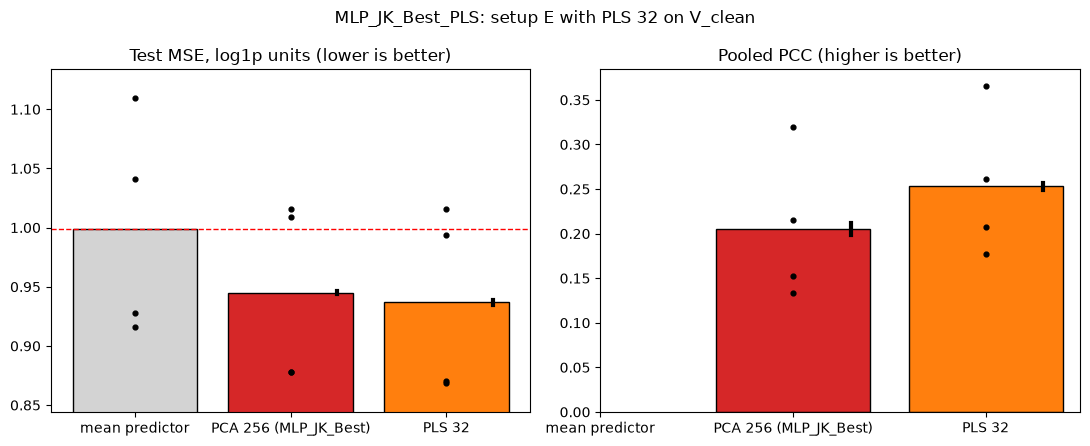

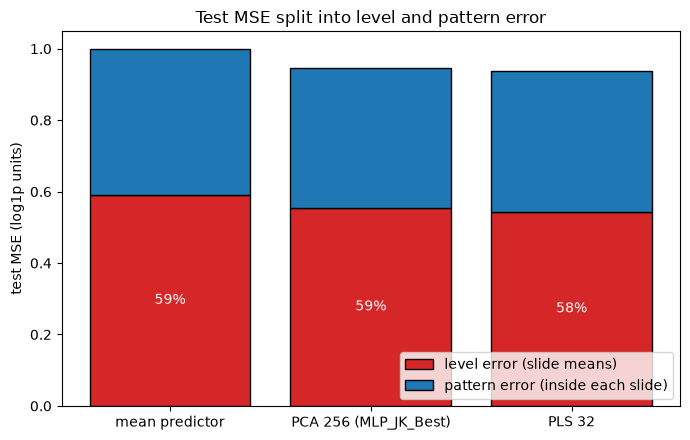

In [16]:
pca_label = "PCA 256 (MLP_JK_Best)"
pls_label = "PLS 32"
plot_folds = {"mean predictor": mean_folds, pca_label: best_folds.reset_index(), pls_label: pls_folds}
plot_summary = {"mean predictor": summary.set_index("model").loc["mean predictor"], pca_label: best_summary,
                pls_label: summary.set_index("model").loc[MODEL_NAME]}
colors = {"mean predictor": "lightgrey", pca_label: "tab:red", pls_label: "tab:orange"}
plot_models = list(colors)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, column, summary_column, seed_column, title in [
        (axes[0], "MSE", "test_MSE", "seed_range_test_MSE", "Test MSE, log1p units (lower is better)"),
        (axes[1], "PCC", "pooled_PCC", "seed_range_pooled_PCC", "Pooled PCC (higher is better)")]:
    for i, name in enumerate(plot_models):
        values = plot_folds[name][column]
        if values.notna().any():
            ax.bar(i, values.mean(), color=colors[name], edgecolor="black")
            ax.scatter(np.full(len(values), i), values, color="black", s=12, zorder=3)
        row = plot_summary[name]
        if pd.notna(row.get(seed_column)):
            half = row[seed_column] / 2
            ax.plot([i + 0.3, i + 0.3], [row[summary_column] - half, row[summary_column] + half], color="black", linewidth=3)
    ax.set_xticks(range(len(plot_models)))
    ax.set_xticklabels(plot_models)
    ax.set_title(title)
axes[0].axhline(mean_overall["test_MSE"], color="red", linestyle="--", linewidth=1)
all_mse = pd.concat([plot_folds[name]["MSE"] for name in plot_models])
axes[0].set_ylim(all_mse.min() - 0.1 * (all_mse.max() - all_mse.min()), all_mse.max() + 0.1 * (all_mse.max() - all_mse.min()))
fig.suptitle(f"MLP_JK_Best_PLS: setup E with PLS 32 on {GENE_LIST}")
plt.tight_layout()
save_figure("1_mse_and_pcc.png")
plt.show()

fig, ax = plt.subplots(figsize=(7, 4.5))
x = np.arange(len(plot_models))
level = [plot_summary[name]["level_error"] for name in plot_models]
pattern = [plot_summary[name]["pattern_error"] for name in plot_models]
ax.bar(x, level, color="tab:red", edgecolor="black", label="level error (slide means)")
ax.bar(x, pattern, bottom=level, color="tab:blue", edgecolor="black", label="pattern error (inside each slide)")
for i, name in enumerate(plot_models):
    ax.text(i, level[i] / 2, f"{plot_summary[name]['level_share']:.0%}", ha="center", va="center", color="white")
ax.set_xticks(x)
ax.set_xticklabels(plot_models)
ax.set_ylabel("test MSE (log1p units)")
ax.set_title("Test MSE split into level and pattern error")
ax.legend(loc="lower right")
plt.tight_layout()
save_figure("2_error_split.png")
plt.show()

## Step 13. Save results, add to the log, write the two references

`all_results.csv` gets one row (`E 5x5 average | PLS k=32`). Only this notebook's row is written: the other lines of the file are kept exactly as they are. If this notebook is run again, its old row is replaced instead of duplicated.

`best_references.json` holds both reference models and the bar a new experiment must clear: **validation PCC above the higher of the two references, and validation NRMSE no worse than the mean predictor's.** Future notebooks read this file and report their scores against both references. Test scores are reported, never used to choose.

In [17]:
os.makedirs(OUT_DIR, exist_ok=True)
summary.to_csv(os.path.join(OUT_DIR, "summary.csv"), index=False)
fold_scores.to_csv(os.path.join(OUT_DIR, "fold_scores.csv"), index=False)
val_scores.to_csv(os.path.join(OUT_DIR, "validation_scores.csv"), index=False)
chosen_settings.to_csv(os.path.join(OUT_DIR, "chosen_settings.csv"), index=False)
reproduction_check.to_csv(os.path.join(OUT_DIR, "reproduction_check.csv"), index=False)
comparison.to_csv(os.path.join(OUT_DIR, "comparison_with_PCA.csv"), index=False)
pooled.to_csv(os.path.join(OUT_DIR, "pooled_gene_scores.csv"), index=False)
within.to_csv(os.path.join(OUT_DIR, "within_patient_gene_scores.csv"), index=False)
pd.DataFrame([{"fold": fold, "rank": rank, "ensembl_id": gene, "symbol": symbol_of[gene]}
              for fold in range(N_FOLDS) for rank, gene in enumerate(all_genes[fold_genes[fold]])]
             ).to_csv(os.path.join(OUT_DIR, "genes.csv"), index=False)

settings = {
    "notebook": NOTEBOOK_NAME,
    "model": MODEL_NAME,
    "from_notebook": "MLP_JK_11_projection_comparison (PLS, k=32)",
    "projection": "kernel PLS (Dayal & MacGregor 1997) in numpy, reproducing sklearn PLSRegression (scale=True); "
                  "one fit per block (center, 5x5 average); outputs unscaled",
    "n_components_per_block": N_COMPONENTS,
    "pls_fit_rows": "validation: each inner group's fit patients; test: all of the fold's training patients",
    "gene_rule": gene_rule,
    "neighbor_distance": NEIGHBOR_DISTANCE,
    "n_folds": N_FOLDS,
    "min_test_sd": MIN_TEST_SD,
    "seed": SEED,
    "hidden_size": HIDDEN_SIZE,
    "dropout": DROPOUT,
    "weight_decay": WEIGHT_DECAY,
    "learning_rate": LEARNING_RATE,
    "batch_size": BATCH_SIZE,
    "max_epochs": MAX_EPOCHS,
    "patience": PATIENCE,
    "shrink_factors": SHRINK_FACTORS,
    "n_val_groups": N_VAL_GROUPS,
    "n_final_seeds": N_FINAL_SEEDS,
    "device": str(device),
    "torch_version": torch.__version__,
}
with open(os.path.join(OUT_DIR, "settings.json"), "w") as f:
    json.dump(settings, f, indent=2, default=str)

today = datetime.date.today().isoformat()
if LOG_RESULTS:
    log_row = {"notebook": NOTEBOOK_NAME, "condition": "E 5x5 average | PLS k=32",
               "pooled_PCC": pls_overall["pooled_PCC"], "within_patient_PCC": pls_overall["within_PCC"],
               "NRMSE": pls_overall["NRMSE"], "mean_predictor_NRMSE": mean_overall["NRMSE"],
               "val_PCC": pls_row["val_PCC"], "val_NRMSE": pls_row["val_NRMSE"],
               "date": today, "target": "raw", "gene_list": GENE_LIST}
    with open(RESULTS_LOG) as f:
        lines = f.readlines()
    columns = lines[0].strip().split(",")
    kept = [line for line in lines if not line.startswith(NOTEBOOK_NAME + ",")]
    new_line = pd.DataFrame([log_row])[columns].to_csv(header=False, index=False)
    with open(RESULTS_LOG, "w") as f:
        f.writelines(kept + [new_line])
    print("Added 1 row to all_results.csv (other rows left as they were)")


def reference_entry(row, notebook, setup, n_inputs):
    entry = {"notebook": notebook, "setup": setup, "summary_file": f"results/{notebook}/summary.csv",
             "summary_model": row.name, "head_inputs": n_inputs, "head_weights": head_weights(n_inputs)}
    for metric in ["val_PCC", "val_NRMSE", "test_MSE", "pooled_PCC", "within_PCC", "NRMSE", "level_error", "pattern_error"]:
        entry[metric] = float(row[metric])
    return entry


pls_summary = summary.set_index("model").loc[MODEL_NAME]
references = {
    "MLP_JK_Best": reference_entry(best_summary, "MLP_JK_Best", "E (center + 5x5 average) + PCA 256 per block", 512),
    "MLP_JK_Best_PLS": reference_entry(pls_summary, "MLP_JK_Best_PLS", "E (center + 5x5 average) + kernel PLS 32 per block",
                                       2 * N_COMPONENTS),
}
mean_predictor_val_NRMSE = float(pls_summary["val_mean_predictor_NRMSE"])
best_references = {
    "updated": today,
    "references": references,
    "mean_predictor": {"val_NRMSE": mean_predictor_val_NRMSE, "test_MSE": float(mean_overall["test_MSE"]),
                       "NRMSE": float(mean_overall["NRMSE"])},
    "bar_to_beat": {"val_PCC_above": max(r["val_PCC"] for r in references.values()),
                    "val_NRMSE_at_most": mean_predictor_val_NRMSE},
    "rule": "A new setting beats the references only if its validation PCC is above bar_to_beat.val_PCC_above "
            "and its validation NRMSE is at most bar_to_beat.val_NRMSE_at_most (the mean predictor's). "
            "Validation = patient-grouped inner validation on training patients. Test scores are reported, never used to choose. "
            "Report every new experiment against both references.",
}
with open(REFERENCES_FILE, "w") as f:
    json.dump(best_references, f, indent=2)
print(json.dumps(best_references["bar_to_beat"], indent=2))

print("\nSaved to", OUT_DIR)
for name in sorted(os.listdir(OUT_DIR)):
    print("  ", name)

Added 1 row to all_results.csv
{
  "val_PCC_above": 0.23851826547913912,
  "val_NRMSE_at_most": 1.1127891540527344
}

Saved to /Users/jk/JHU/BDD/MLP_JK/results/MLP_JK_Best_PLS
   1_mse_and_pcc.png
   2_error_split.png
   chosen_settings.csv
   comparison_with_PCA.csv
   fold_scores.csv
   genes.csv
   pooled_gene_scores.csv
   reproduction_check.csv
   settings.json
   summary.csv
   validation_scores.csv
   within_patient_gene_scores.csv


## Summary in plain words

**The check passed.** This notebook gives exactly MLP_JK_11's "PLS k=32" numbers: all 6 scores match to 4 decimals, and the chosen `s` (0.6/0.4/0.6/0.4) and epochs (34/28/25/26) match in every fold. The whole run took about 3.5 minutes.

**PLS 32 vs. PCA 256 (MLP_JK_Best):**

| | PCA 256 | PLS 32 | PLS − PCA |
|---|---|---|---|
| Validation PCC | 0.2376 | 0.2385 | +0.0009 |
| Validation NRMSE | 1.0804 | 1.0767 | −0.0037 |
| Test MSE | 0.9451 | 0.9369 | −0.0082 |
| Pooled PCC | 0.2053 | 0.2529 | +0.0476 |
| Within-patient PCC | 0.1731 | 0.1762 | +0.0031 |
| NRMSE | 1.0673 | 1.0625 | −0.0049 |
| Level error | 0.5550 | 0.5442 | −0.0108 |
| Pattern error | 0.3901 | 0.3927 | +0.0026 |
| Inputs to the head | 512 | 64 | |
| Head weights | 72,114 | 14,770 | |

- **On validation, the two tie.** PLS is ahead in 3 of 4 folds and behind in fold 3 (−0.012). The overall gap (+0.0009) is far below what we'd call real.
- **On test, PLS has a higher pooled PCC in all 4 folds** (+0.044 to +0.055). Its test MSE is lower in 3 of 4 folds.
- **The gain is in getting each slide's overall level right.** Level error drops by 0.011; pattern error is about the same (+0.003). Within-patient PCC is about equal: +0.003 overall, 2 folds up and 2 down.
- **PLS is much smaller.** It gives the head 64 numbers per spot instead of 512, so the head has about 5 times fewer weights. But PLS uses the genes, so it must be refit for every set of training patients. PCA doesn't, and it is faster to fit.

**What changes from here.** We keep both models as references. `results/best_references.json` holds both, and the bar a new experiment must clear: validation PCC above 0.2385 and validation NRMSE no worse than the mean predictor's (1.1128). New experiments report their scores against both references. MLP_JK_Best itself is unchanged.